# 02 — Exploratory Data Analysis (EDA)
## Analisis Eksploratif Dataset Covertype

Tujuan EDA adalah memahami struktur, kualitas, distribusi, dan pola data sebelum melakukan preprocessing dan pemodelan. Setiap grafik perlu diikuti interpretasi berdasarkan hasil yang benar-benar terlihat.

## 1. Import library dan memuat data

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)


from pathlib import Path
import pandas as pd
import numpy as np

NUMERIC_FEATURES = [
    "Elevation", "Aspect", "Slope", "Horizontal_Distance_To_Hydrology",
    "Vertical_Distance_To_Hydrology", "Horizontal_Distance_To_Roadways",
    "Hillshade_9am", "Hillshade_Noon", "Hillshade_3pm",
    "Horizontal_Distance_To_Fire_Points"
]
WILDERNESS_COLS = [f"Wilderness_Area{i}" for i in range(1, 5)]
SOIL_COLS = [f"Soil_Type{i}" for i in range(1, 41)]
TARGET_COL = "Cover_Type"
COLUMNS = NUMERIC_FEATURES + WILDERNESS_COLS + SOIL_COLS + [TARGET_COL]

DATA_CANDIDATES = [
    Path("covtype.data"),
    Path("data") / "covtype.data",
    Path("../covtype.data"),
    Path("../data") / "covtype.data",
]
DATA_PATH = next((path for path in DATA_CANDIDATES if path.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "File covtype.data tidak ditemukan. Letakkan file tersebut di folder "
        "yang sama dengan notebook atau di subfolder 'data/'."
    )

df = pd.read_csv(DATA_PATH, header=None, names=COLUMNS)
print(f"Dataset berhasil dimuat dari: {DATA_PATH.resolve()}")
print(f"Ukuran dataset: {df.shape[0]:,} baris x {df.shape[1]} kolom")

Dataset berhasil dimuat dari: C:\Users\parsey\Downloads\Covertype_4_Phase_Notebooks\covtype.data
Ukuran dataset: 581,012 baris x 55 kolom


## 2. Struktur dan statistik deskriptif

In [2]:
print("Ukuran data:", df.shape)
display(df.head())
display(df.describe().T)

Ukuran data: (581012, 55)


,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
0,2596,51,3,258,0,510,221,232,148,6279,...,0,0,0,0,0,0,0,0,0,5
1,2590,56,2,212,-6,390,220,235,151,6225,...,0,0,0,0,0,0,0,0,0,5
2,2804,139,9,268,65,3180,234,238,135,6121,...,0,0,0,0,0,0,0,0,0,2
3,2785,155,18,242,118,3090,238,238,122,6211,...,0,0,0,0,0,0,0,0,0,2
4,2595,45,2,153,-1,391,220,234,150,6172,...,0,0,0,0,0,0,0,0,0,5


,count,mean,std,min,25%,50%,75%,max
Elevation,581012.0,2959.365301,279.984734,1859.0,2809.0,2996.0,3163.0,3858.0
Aspect,581012.0,155.656807,111.913721,0.0,58.0,127.0,260.0,360.0
Slope,581012.0,14.103704,7.488242,0.0,9.0,13.0,18.0,66.0
Horizontal_Distance_To_Hydrology,581012.0,269.428217,212.549356,0.0,108.0,218.0,384.0,1397.0
Vertical_Distance_To_Hydrology,581012.0,46.418855,58.295232,-173.0,7.0,30.0,69.0,601.0
Horizontal_Distance_To_Roadways,581012.0,2350.146611,1559.254870,0.0,1106.0,1997.0,3328.0,7117.0
Hillshade_9am,581012.0,212.146049,26.769889,0.0,198.0,218.0,231.0,254.0
Hillshade_Noon,581012.0,223.318716,19.768697,0.0,213.0,226.0,237.0,254.0
Hillshade_3pm,581012.0,142.528263,38.274529,0.0,119.0,143.0,168.0,254.0
Horizontal_Distance_To_Fire_Points,581012.0,1980.291226,1324.195210,0.0,1024.0,1710.0,2550.0,7173.0


### Interpretasi statistik deskriptif

Dataset berisi **581.012 observasi**. Rata-rata `Elevation` adalah sekitar **2.959,37 meter** dengan standar deviasi **279,98 meter**. Rata-rata `Slope` sekitar **14,10°**, sedangkan median jarak horizontal ke jalan (`Horizontal_Distance_To_Roadways`) adalah **1.997 meter**. Rentang fitur sangat berbeda: `Elevation` berkisar 1.859–3.858 meter, sedangkan jarak ke titik api berkisar 0–7.173 meter.

Perbedaan satuan dan skala ini perlu diingat saat memilih model. Model berbasis pohon yang digunakan di notebook modelling tidak mensyaratkan standardisasi fitur, sedangkan model berbasis jarak atau model linear tertentu biasanya lebih sensitif terhadap skala.

Kolom `Cover_Type` memang bertipe angka, tetapi nilainya adalah kode kelas nominal. Rata-rata kode target bukan ukuran “rata-rata jenis hutan” yang bermakna.

## 3. Kualitas data

In [3]:
missing = df.isna().sum().sort_values(ascending=False)
print("Total missing values:", int(missing.sum()))
display(missing[missing > 0])

duplicate_count = int(df.duplicated().sum())
print("Jumlah baris duplikat:", duplicate_count)

print("\nRentang target:")
print("Minimum:", df[TARGET_COL].min(), "| Maksimum:", df[TARGET_COL].max())

Total missing values: 0


Series([], dtype: int64)

Jumlah baris duplikat: 0

Rentang target:
Minimum: 1 | Maksimum: 7


### Interpretasi pemeriksaan kualitas

Hasil pemeriksaan menunjukkan **0 missing value** dan **0 baris duplikat**. Target memiliki nilai minimum 1 dan maksimum 7, sesuai dengan tujuh kelas tutupan hutan yang didokumentasikan. Dengan demikian, pada dataset yang diuji tidak diperlukan imputasi maupun penghapusan baris duplikat. Pemeriksaan ini tidak berarti seluruh aspek data pasti bebas kesalahan; validasi rentang dan konsistensi indikator tetap dilakukan pada preprocessing.

## 4. Distribusi target `Cover_Type`

Ketidakseimbangan kelas dapat membuat accuracy terlihat tinggi meskipun model gagal mengenali kelas yang jumlahnya sedikit. Karena itu, distribusi target menjadi pemeriksaan penting sebelum pemodelan.

,Nama kelas,Jumlah,Persentase (%)
Cover_Type,,,
1,Spruce/Fir,211840,36.46
2,Lodgepole Pine,283301,48.76
3,Ponderosa Pine,35754,6.15
4,Cottonwood/Willow,2747,0.47
5,Aspen,9493,1.63
6,Douglas-fir,17367,2.99
7,Krummholz,20510,3.53


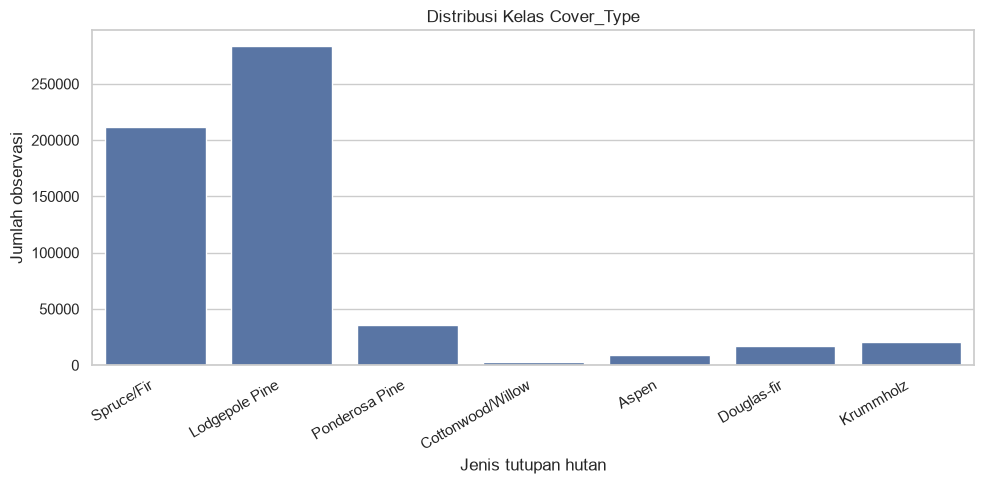

Kelas mayoritas: 2 (Lodgepole Pine), 48.76%
Kelas minoritas: 4 (Cottonwood/Willow), 0.47%


In [4]:
CLASS_NAMES = {
    1: "Spruce/Fir",
    2: "Lodgepole Pine",
    3: "Ponderosa Pine",
    4: "Cottonwood/Willow",
    5: "Aspen",
    6: "Douglas-fir",
    7: "Krummholz"
}

class_counts = df[TARGET_COL].value_counts().sort_index()
class_percent = (class_counts / len(df) * 100).round(2)

class_summary = pd.DataFrame({
    "Nama kelas": [CLASS_NAMES.get(int(i), str(i)) for i in class_counts.index],
    "Jumlah": class_counts.values,
    "Persentase (%)": class_percent.values
}, index=class_counts.index)
class_summary.index.name = "Cover_Type"
display(class_summary)

plt.figure(figsize=(10, 5))
ax = sns.barplot(x=class_summary["Nama kelas"], y=class_summary["Jumlah"])
ax.set_title("Distribusi Kelas Cover_Type")
ax.set_xlabel("Jenis tutupan hutan")
ax.set_ylabel("Jumlah observasi")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

majority_class = int(class_counts.idxmax())
minority_class = int(class_counts.idxmin())
print(f"Kelas mayoritas: {majority_class} ({CLASS_NAMES[majority_class]}), "
      f"{class_percent.loc[majority_class]}%")
print(f"Kelas minoritas: {minority_class} ({CLASS_NAMES[minority_class]}), "
      f"{class_percent.loc[minority_class]}%")

### Interpretasi grafik distribusi kelas `Cover_Type`

Grafik memperlihatkan ketidakseimbangan kelas yang kuat.

- **Lodgepole Pine (kelas 2)** adalah kelas mayoritas: **283.301 observasi (48,76%)**.
- **Spruce/Fir (kelas 1)** berada di urutan kedua: **211.840 observasi (36,46%)**.
- Kedua kelas tersebut mencakup sekitar **85,22%** seluruh data.
- **Cottonwood/Willow (kelas 4)** adalah kelas minoritas: **2.747 observasi (0,47%)**.

Jumlah Lodgepole Pine sekitar 103 kali jumlah Cottonwood/Willow. Jika model selalu menebak kelas mayoritas, accuracy-nya saja sudah sekitar 48,76%, tetapi model tersebut sama sekali tidak mengenali enam kelas lainnya. Karena itu, accuracy tidak boleh menjadi satu-satunya metrik. Macro-F1, balanced accuracy, recall per kelas, dan confusion matrix diperlukan untuk melihat performa pada seluruh kelas.

## 5. Distribusi fitur numerik

Histogram digunakan untuk melihat bentuk distribusi, kemencengan (skewness), rentang, dan kemungkinan nilai ekstrem pada fitur numerik.

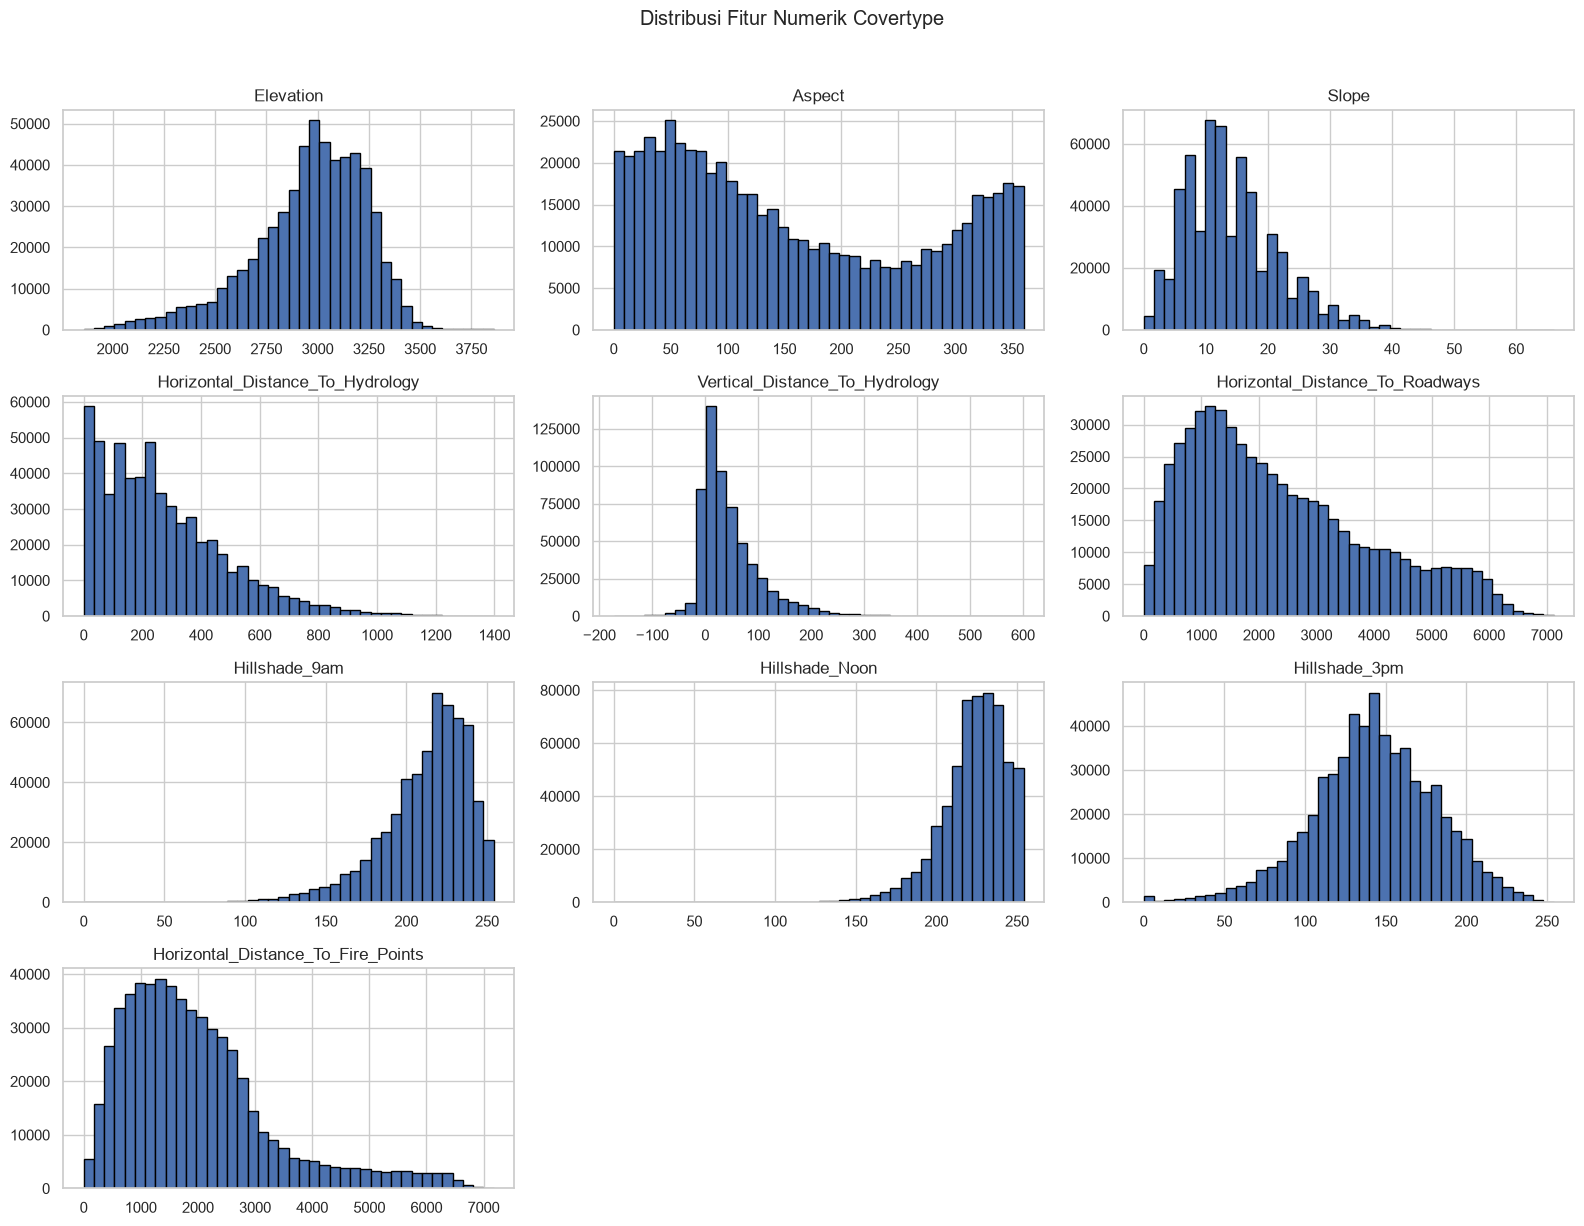

,Skewness
Vertical_Distance_To_Hydrology,1.790250
Horizontal_Distance_To_Fire_Points,1.288644
Horizontal_Distance_To_Hydrology,1.140437
Slope,0.789273
Horizontal_Distance_To_Roadways,0.713679
Aspect,0.402628
Hillshade_3pm,-0.277053
Elevation,-0.817596
Hillshade_Noon,-1.063056
Hillshade_9am,-1.181147


In [5]:
NUMERIC_FEATURES = [
    "Elevation", "Aspect", "Slope", "Horizontal_Distance_To_Hydrology",
    "Vertical_Distance_To_Hydrology", "Horizontal_Distance_To_Roadways",
    "Hillshade_9am", "Hillshade_Noon", "Hillshade_3pm",
    "Horizontal_Distance_To_Fire_Points"
]

df[NUMERIC_FEATURES].hist(
    bins=40, figsize=(16, 12), edgecolor="black"
)
plt.suptitle("Distribusi Fitur Numerik Covertype", y=1.02)
plt.tight_layout()
plt.show()

skewness = df[NUMERIC_FEATURES].skew().sort_values(ascending=False)
display(skewness.to_frame("Skewness"))

### Interpretasi histogram dan skewness fitur numerik

Histogram memperlihatkan bentuk distribusi yang berbeda-beda.

- `Elevation` terkonsentrasi di sekitar 2.800–3.300 meter dan sedikit menceng ke kiri (skewness **-0,82**).
- `Aspect` tersebar pada rentang 0–360° dan memiliki pola melingkar/nonlinier. Angka 0° dan 360° adalah arah yang sama, sehingga histogramnya tidak tepat diperlakukan seperti fitur linear biasa.
- `Slope` menceng ke kanan (skewness **0,79**); sebagian besar lereng berada pada nilai rendah hingga menengah, dengan sebagian kecil lebih curam.
- Jarak horizontal ke hidrologi, jalan, dan titik api cenderung menceng ke kanan. Banyak observasi memiliki jarak relatif pendek, sementara sebagian observasi memiliki jarak yang jauh.
- `Vertical_Distance_To_Hydrology` paling menceng ke kanan (skewness **1,79**). Mayoritas nilainya terkonsentrasi pada nilai rendah, tetapi terdapat ekor hingga nilai positif yang besar dan juga nilai negatif.
- `Hillshade_9am` dan `Hillshade_Noon` menceng ke kiri (masing-masing sekitar **-1,18** dan **-1,06**), karena banyak observasi berada pada nilai indeks yang relatif tinggi.
- `Hillshade_3pm` lebih mendekati bentuk lonceng dibandingkan dua indeks hillshade lainnya (skewness sekitar **-0,28**).

Skewness menunjukkan bentuk distribusi, bukan bukti bahwa data salah. Ekor panjang pada fitur jarak dapat menggambarkan kondisi geografis yang memang jarang.

## 6. Deteksi outlier menggunakan IQR

Batas IQR dipakai sebagai penanda statistik, bukan sebagai keputusan otomatis untuk menghapus observasi.

In [6]:
q1 = df[NUMERIC_FEATURES].quantile(0.25)
q3 = df[NUMERIC_FEATURES].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outlier_count = (
    (df[NUMERIC_FEATURES] < lower_bound) |
    (df[NUMERIC_FEATURES] > upper_bound)
).sum()

outlier_summary = pd.DataFrame({
    "Jumlah outlier IQR": outlier_count,
    "Persentase (%)": (outlier_count / len(df) * 100).round(2),
    "Batas bawah": lower_bound,
    "Batas atas": upper_bound
}).sort_values("Jumlah outlier IQR", ascending=False)

display(outlier_summary)

,Jumlah outlier IQR,Persentase (%),Batas bawah,Batas atas
Vertical_Distance_To_Hydrology,31463,5.42,-86.0,162.0
Horizontal_Distance_To_Fire_Points,31157,5.36,-1265.0,4839.0
Hillshade_9am,17433,3.00,148.5,280.5
Hillshade_Noon,15672,2.70,177.0,273.0
Elevation,15569,2.68,2278.0,3694.0
Slope,15316,2.64,-4.5,31.5
Horizontal_Distance_To_Hydrology,14557,2.51,-306.0,798.0
Hillshade_3pm,7832,1.35,45.5,241.5
Horizontal_Distance_To_Roadways,669,0.12,-2227.0,6661.0
Aspect,0,0.00,-245.0,563.0


### Interpretasi hasil deteksi outlier IQR

Fitur dengan jumlah penanda outlier IQR terbanyak adalah:

- `Vertical_Distance_To_Hydrology`: **31.463 (5,42%)**.
- `Horizontal_Distance_To_Fire_Points`: **31.157 (5,36%)**.
- `Hillshade_9am`: **17.433 (3,00%)**.
- `Hillshade_Noon`: **15.672 (2,70%)**.
- `Elevation`: **15.569 (2,68%)**.

`Horizontal_Distance_To_Roadways` memiliki penanda outlier paling sedikit, yaitu **669 (0,12%)**. `Aspect` tidak ditandai sebagai outlier oleh IQR, tetapi hal itu tidak berarti IQR merupakan metode yang ideal untuk variabel sudut. Variabel melingkar memiliki karakteristik khusus yang tidak sepenuhnya ditangkap oleh batas kuartil linear.

IQR hanya menandai nilai yang jauh dari kuartil, bukan memastikan nilai tersebut salah. Pada data topografi, jarak yang sangat jauh, elevasi ekstrem, atau posisi relatif terhadap sumber air dapat merupakan kondisi yang valid. Karena tidak ada bukti kesalahan pencatatan, nilai-nilai tersebut tidak otomatis dihapus pada tahap preprocessing.

## 7. Boxplot fitur numerik

Untuk mengurangi beban visualisasi, boxplot menggunakan sampel acak. Ringkasan outlier pada bagian sebelumnya tetap dihitung dari seluruh data.

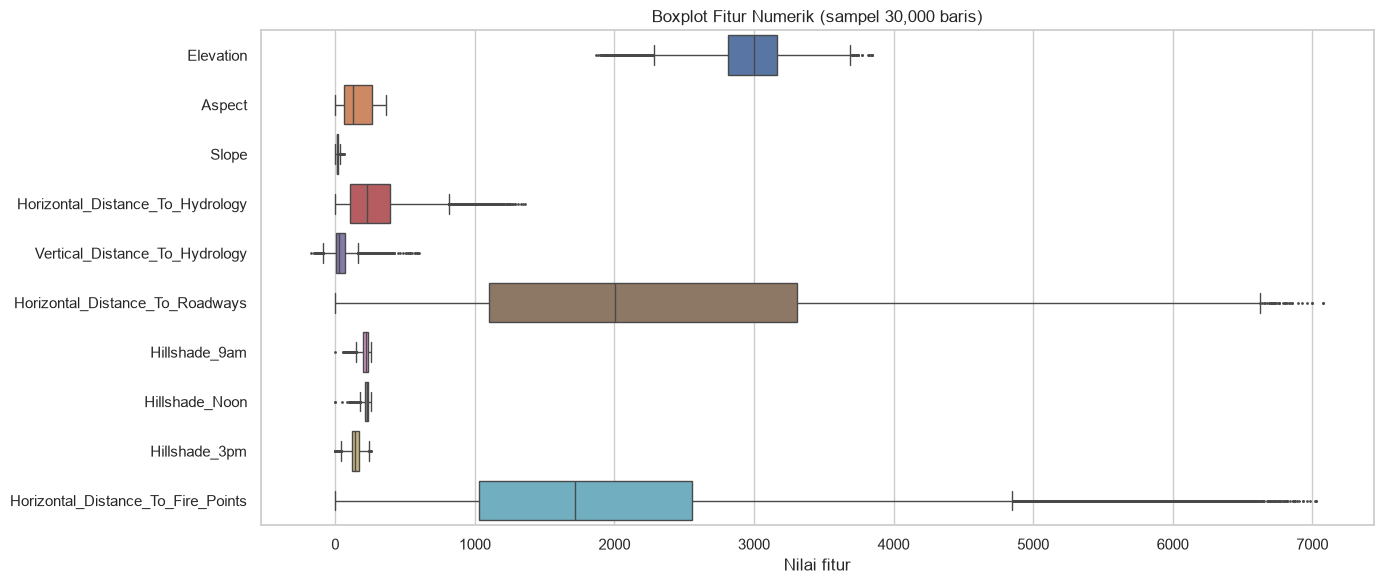

In [7]:
sample_size = min(30000, len(df))
df_sample = df.sample(n=sample_size, random_state=42)

plt.figure(figsize=(14, 6))
sns.boxplot(data=df_sample[NUMERIC_FEATURES], orient="h", fliersize=1)
plt.title(f"Boxplot Fitur Numerik (sampel {sample_size:,} baris)")
plt.xlabel("Nilai fitur")
plt.tight_layout()
plt.show()

### Interpretasi boxplot fitur numerik

Boxplot dari sampel 30.000 baris memperlihatkan bahwa `Horizontal_Distance_To_Roadways` memiliki rentang dan sebaran yang lebar. `Horizontal_Distance_To_Fire_Points` juga memperlihatkan ekor panjang dan banyak nilai ekstrem. `Vertical_Distance_To_Hydrology` memiliki kotak yang relatif sempit dibanding rentang keseluruhannya, dengan sejumlah titik di luar whisker.

Fitur hillshade dan `Aspect` terlihat lebih terkonsentrasi karena rentang angkanya lebih kecil daripada fitur jarak. Karena seluruh fitur digambar pada satu sumbu nilai yang sama meskipun satuannya berbeda, lebar kotak antarfitur tidak boleh dibandingkan sebagai ukuran variasi yang setara. Boxplot ini terutama dipakai untuk melihat bentuk sebaran dan kandidat nilai ekstrem pada tiap fitur.

## 8. Korelasi antar fitur numerik

Heatmap Pearson digunakan sebagai pemeriksaan hubungan linear antarfitur numerik. Korelasi rendah terhadap target tidak otomatis berarti fitur tidak berguna, karena model pohon dapat memanfaatkan pola nonlinier dan interaksi.

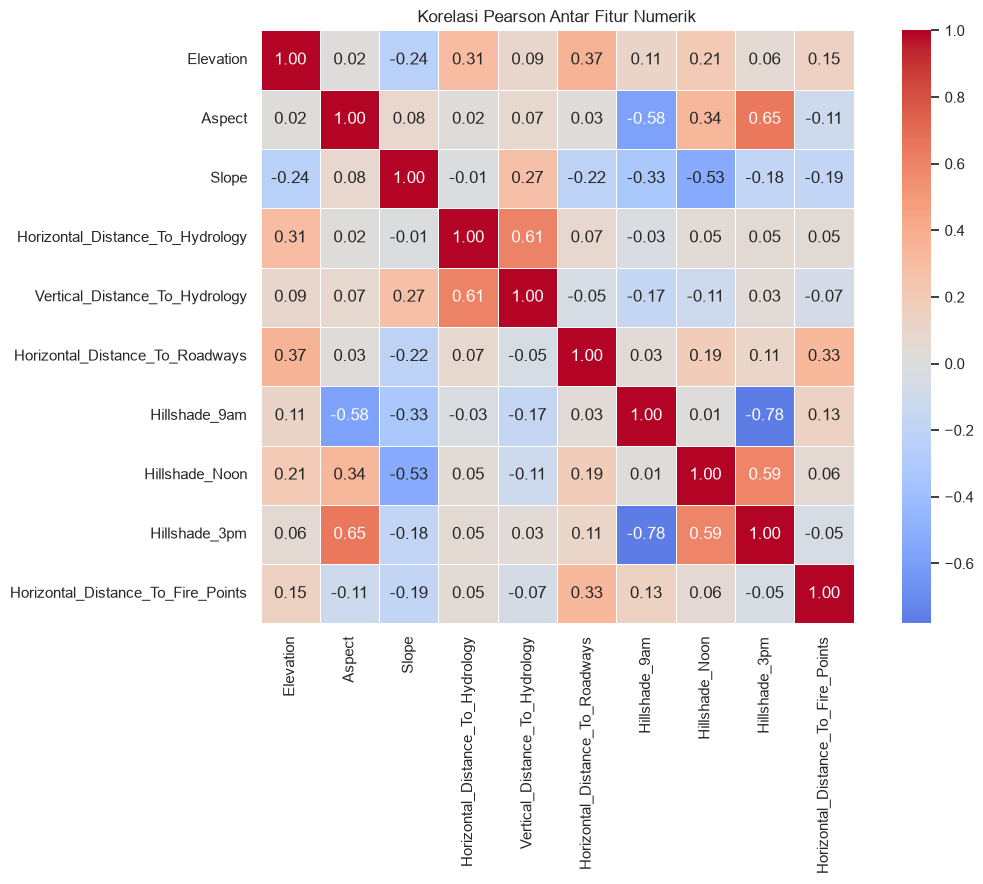

,Fitur 1,Fitur 2,correlation
68,Hillshade_9am,Hillshade_3pm,-0.780296
18,Aspect,Hillshade_3pm,0.646944
34,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,0.606236
78,Hillshade_Noon,Hillshade_3pm,0.594274
16,Aspect,Hillshade_9am,-0.579273
27,Slope,Hillshade_Noon,-0.526911
5,Elevation,Horizontal_Distance_To_Roadways,0.365559
17,Aspect,Hillshade_Noon,0.336103
59,Horizontal_Distance_To_Roadways,Horizontal_Distance_To_Fire_Points,0.331580
26,Slope,Hillshade_9am,-0.327199


In [8]:
corr = df[NUMERIC_FEATURES].corr(method="pearson")

plt.figure(figsize=(12, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f",
            square=True, linewidths=0.4)
plt.title("Korelasi Pearson Antar Fitur Numerik")
plt.tight_layout()
plt.show()

corr_pairs = (
    corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
        .stack()
        .rename("correlation")
        .reset_index()
        .rename(columns={"level_0": "Fitur 1", "level_1": "Fitur 2"})
)
display(corr_pairs.reindex(corr_pairs["correlation"].abs().sort_values(ascending=False).index).head(15))

### Interpretasi heatmap korelasi Pearson

Pasangan dengan korelasi absolut terbesar adalah:

- `Hillshade_9am` dengan `Hillshade_3pm`: **-0,78** (hubungan negatif kuat).
- `Aspect` dengan `Hillshade_3pm`: **0,65**.
- `Horizontal_Distance_To_Hydrology` dengan `Vertical_Distance_To_Hydrology`: **0,61**.
- `Hillshade_Noon` dengan `Hillshade_3pm`: **0,59**.
- `Aspect` dengan `Hillshade_9am`: **-0,58**.
- `Slope` dengan `Hillshade_Noon`: **-0,53**.

Korelasi tersebut masuk akal sebagai hubungan antarvariabel lingkungan/topografi yang saling berkaitan, khususnya indeks hillshade dengan arah lereng. Tidak ada pasangan pada heatmap ini yang mencapai nilai absolut 0,80. Oleh karena itu, tidak ada dasar kuat untuk langsung menghapus salah satu fitur hanya karena multikolinearitas ekstrem.

Korelasi Pearson hanya mengukur hubungan linear antarfitur numerik. Korelasi rendah tidak berarti suatu fitur tidak berguna untuk klasifikasi, karena hubungan fitur dengan target dapat bersifat nonlinier atau melibatkan interaksi.

## 9. Distribusi fitur one-hot

Empat kolom Wilderness Area dan 40 kolom Soil Type adalah indikator biner. Jumlah nilai 1 menunjukkan banyaknya observasi yang masuk kategori tersebut.

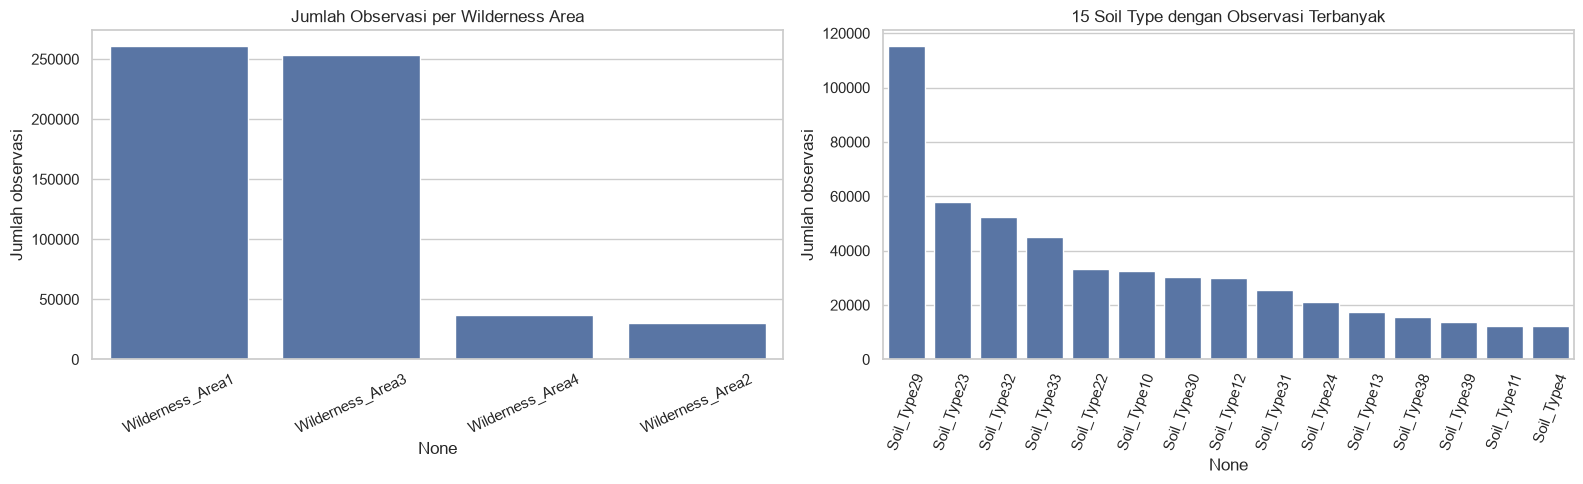

Jumlah indikator Wilderness aktif per baris:


1    581012
Name: count, dtype: int64

Jumlah indikator Soil aktif per baris:


1    581012
Name: count, dtype: int64

In [9]:
WILDERNESS_COLS = [f"Wilderness_Area{i}" for i in range(1, 5)]
SOIL_COLS = [f"Soil_Type{i}" for i in range(1, 41)]

wilderness_counts = df[WILDERNESS_COLS].sum().sort_values(ascending=False)
soil_counts = df[SOIL_COLS].sum().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(x=wilderness_counts.index, y=wilderness_counts.values, ax=axes[0])
axes[0].set_title("Jumlah Observasi per Wilderness Area")
axes[0].set_ylabel("Jumlah observasi")
axes[0].tick_params(axis="x", rotation=25)

top_soils = soil_counts.head(15)
sns.barplot(x=top_soils.index, y=top_soils.values, ax=axes[1])
axes[1].set_title("15 Soil Type dengan Observasi Terbanyak")
axes[1].set_ylabel("Jumlah observasi")
axes[1].tick_params(axis="x", rotation=70)

plt.tight_layout()
plt.show()

print("Jumlah indikator Wilderness aktif per baris:")
display(df[WILDERNESS_COLS].sum(axis=1).value_counts().sort_index())
print("Jumlah indikator Soil aktif per baris:")
display(df[SOIL_COLS].sum(axis=1).value_counts().sort_index())

### Interpretasi distribusi fitur one-hot

Grafik Wilderness Area menunjukkan bahwa:

- `Wilderness_Area1`: **260.796 observasi**.
- `Wilderness_Area3`: **253.364 observasi**.
- `Wilderness_Area4`: **36.968 observasi**.
- `Wilderness_Area2`: **29.884 observasi**.

Dengan demikian, sebagian besar observasi berasal dari Area 1 dan Area 3. Pada kelompok Soil Type, `Soil_Type29` paling banyak muncul (**115.247 observasi**), disusul `Soil_Type23` (**57.752**), `Soil_Type32` (**52.519**), dan `Soil_Type33` (**45.154**). Sebaran Soil Type juga tidak merata.

Pemeriksaan di bawah grafik menunjukkan tepat satu indikator Wilderness Area dan tepat satu indikator Soil Type bernilai 1 pada setiap baris. Ini sesuai dengan representasi one-hot yang diharapkan. Kategori yang jarang tetap perlu dipertahankan karena dapat membawa informasi untuk kelas tutupan hutan tertentu.

## 10. Hubungan fitur numerik dengan kelas target

Plot berikut menggunakan sampel agar visualisasi lebih ringan. Perbedaan median dan sebaran antar kelas dapat memberi indikasi bahwa suatu fitur membantu pemisahan kelas.

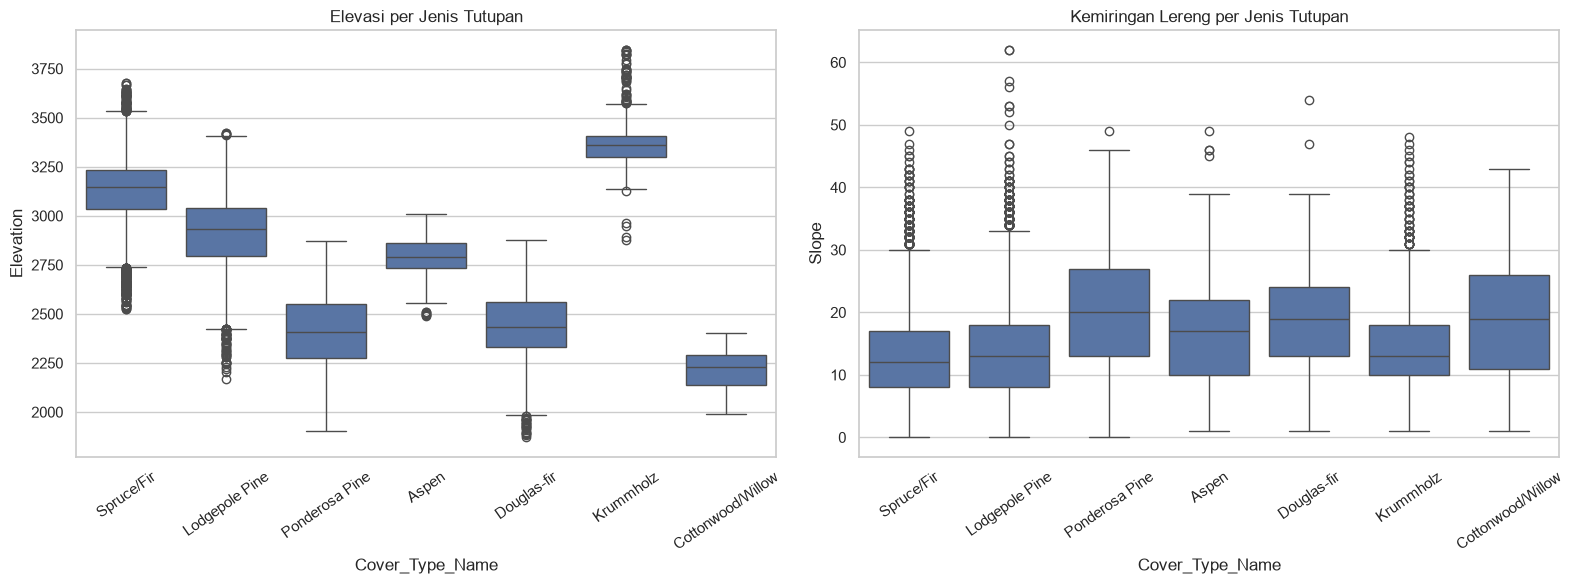

In [10]:
plot_sample = df.sample(n=min(40000, len(df)), random_state=42).copy()
plot_sample["Cover_Type_Name"] = plot_sample[TARGET_COL].map(CLASS_NAMES)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.boxplot(data=plot_sample, x="Cover_Type_Name", y="Elevation", ax=axes[0])
axes[0].set_title("Elevasi per Jenis Tutupan")
axes[0].tick_params(axis="x", rotation=35)

sns.boxplot(data=plot_sample, x="Cover_Type_Name", y="Slope", ax=axes[1])
axes[1].set_title("Kemiringan Lereng per Jenis Tutupan")
axes[1].tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

### Interpretasi boxplot elevasi dan kemiringan per kelas

**Elevasi:** median elevasi tertinggi tampak pada `Krummholz` (sekitar 3.350 meter), diikuti `Spruce/Fir` (sekitar 3.140 meter) dan `Lodgepole Pine` (sekitar 2.930 meter). `Cottonwood/Willow` memiliki median elevasi paling rendah (sekitar 2.220 meter). `Ponderosa Pine` dan `Douglas-fir` berada pada elevasi yang relatif lebih rendah dan distribusinya saling berdekatan.

**Kemiringan lereng:** median `Slope` relatif tinggi pada `Ponderosa Pine` (sekitar 20°), `Douglas-fir` dan `Cottonwood/Willow` (sekitar 19°), sedangkan `Spruce/Fir` dan `Lodgepole Pine` memiliki median lebih rendah (sekitar 12–13°). Sebaran antar kelas tetap saling tumpang tindih.

Pola ini memberi indikasi bahwa elevasi dan slope membantu membedakan kelas, tetapi tidak cukup untuk memisahkan semua kelas secara sempurna. Karena itu, model perlu memanfaatkan beberapa fitur secara bersamaan, termasuk jarak, hillshade, Wilderness Area, dan Soil Type. Boxplot ini menggunakan sampel 40.000 observasi sehingga ditujukan untuk eksplorasi visual, bukan perhitungan statistik final.

## 11. Ringkasan temuan EDA

Berdasarkan output aktual:

1. **Distribusi target:** Lodgepole Pine merupakan kelas terbesar (48,76%), disusul Spruce/Fir (36,46%). Cottonwood/Willow hanya 0,47%. Ketidakseimbangan ini mendukung penggunaan Macro-F1 dan balanced accuracy.
2. **Kualitas data:** tidak ditemukan missing value dan tidak ditemukan baris duplikat.
3. **Outlier:** penanda IQR terbanyak terdapat pada Vertical Distance to Hydrology (5,42%) dan Horizontal Distance to Fire Points (5,36%). Nilai ekstrem dipertahankan karena tidak otomatis merupakan kesalahan data.
4. **Hubungan fitur:** korelasi absolut terbesar adalah Hillshade 9am–Hillshade 3pm (-0,78). Elevation dan slope memperlihatkan median yang berbeda antar kelas, meskipun distribusinya tetap tumpang tindih.
5. **Fitur one-hot:** setiap observasi memiliki tepat satu Wilderness Area dan satu Soil Type aktif. Area 1 dan Area 3 serta Soil Type 29 paling sering muncul.
6. **Implikasi preprocessing:** `Aspect` perlu direpresentasikan sebagai fitur siklik sinus dan cosinus; indikator one-hot divalidasi; data dibagi secara stratified untuk menjaga proporsi tujuh kelas.

**Kesimpulan EDA:** dataset lengkap dan memiliki banyak informasi prediktif, tetapi target sangat tidak seimbang dan beberapa fitur memiliki distribusi menceng serta nilai ekstrem. Tahap preprocessing perlu menjaga validitas nilai geografis sekaligus menyiapkan representasi fitur yang sesuai.